## <1차원 데이터에서의 1차 보간 : 선형 보간(linear Interpolation)>


### 기본 라이브러리 불러오기

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### User parameter 정의하기

In [2]:
# translation
tx, ty = 0, 0
# scaling
sx, sy = 1, 2
# rotation
theta = 0
theta_rad = theta * np.pi / 180

### 동차 행렬 생성하기

In [3]:
# Translation matrix
T = np.array([[1,0,tx],
              [0,1,ty],
              [0,0,1]])

# Scaling matrix
S = np.array([[sx,0,0],
              [0,sy,0],
              [0,0,1]])

# Rotation matrix
R = np.array([[np.cos(theta_rad), -1*np.sin(theta_rad), 0],
              [np.sin(theta_rad), np.cos(theta_rad), 0],
              [0,0,1]])

A = S
print(A)

[[1 0 0]
 [0 2 0]
 [0 0 1]]


### 1차원 데이터 (f) 생성하고, 데이터의 크기(h,w)를 자동으로 구하기

In [4]:
f = np.array([[0,120,180,120,0]])
h,w = f.shape
print(h,w)

1 5


### 결과 데이터 (g) 생성하기

In [5]:
g = np.zeros((int(h*sx), int(w*sy)))
gh,gw = g.shape

## 동차 행렬, 역방향 사상을 기반으로 1차 보간 구현하기

In [6]:
g = np.zeros((int(h*sx), int(w*sy)))
gh,gw = g.shape
for x_prime in range(gh):
    for y_prime in range(gw):
        P_prime = np.array([[x_prime], [y_prime], [1]])
        P = (np.linalg.inv(A)@P_prime) # 실수형

        # 
        Q1 = int(np.floor(P[1,0]))
        Q2 = int(Q1 + 1)
        a = P[1,0] - Q1

        # 계산하기

        if (0 <= Q1 and Q2 < w):
            val = (1-a) * f[0,Q1] + (a) * f[0,Q2]
            g[x_prime,y_prime] = val

g = g.astype("uint8")
print(g)

[[  0  60 120 150 180 150 120  60   0   0]]


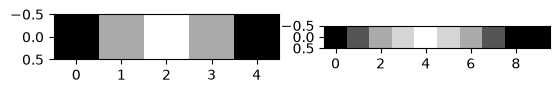

In [7]:
plt.subplot(1,2,1); plt.imshow(f, cmap="gray")
plt.subplot(1,2,2); plt.imshow(g, cmap="gray")